# Análise de Viés Algorítmico em Seleção de Candidatos (XAI)
### Etapa 4: Análise do Atributo Idade

Objetivo: verificar se `Age` influencia as decisões do modelo de forma discriminatória.

Estratégia: 1 - olhar a taxa de aprovação real por faixa etária nos dados; 2 - olhar o impacto SHAP de `Age` por faixa; 3 - comparar com o impacto de `Gender_Male`.

## 1. Carregar modelo, dados e atributos sensíveis

In [1]:
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
import os

PASTA_DADOS = 'dados'

modelo = joblib.load(os.path.join(PASTA_DADOS, 'modelo_random_forest.pkl'))
X_test = pd.read_csv(os.path.join(PASTA_DADOS, 'X_test.csv'), index_col=0)
y_test = pd.read_csv(os.path.join(PASTA_DADOS, 'y_test.csv'), index_col=0).squeeze()
df = pd.read_csv(os.path.join(PASTA_DADOS, 'recruitment_data_fixed.csv'))

print('X_test:', X_test.shape)

C:\Users\fabia\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X_test: (2000, 54)


## 2. Criar faixas etárias

Agrupamos a idade (25 a 55 anos) em três faixas para facilitar a leitura. A primeira faixa é de 25 a 34, a segunda vai de 35 a 44 e a terceira é de 45 a 55 anos.

In [2]:
bins = [24, 34, 44, 55]
labels = ['25-34', '35-44', '45-55']
df['Faixa'] = pd.cut(df['Age'], bins=bins, labels=labels)

print(df['Faixa'].value_counts().sort_index())

Faixa
25-34    3194
35-44    3248
45-55    3558
Name: count, dtype: int64


## 3. Taxa de aprovação real por faixa etária (dados originais)

Faixa
25-34    48.3
35-44    47.8
45-55    49.4
Name: Best Match, dtype: float64

Correlação entre Age e Best Match: 0.01


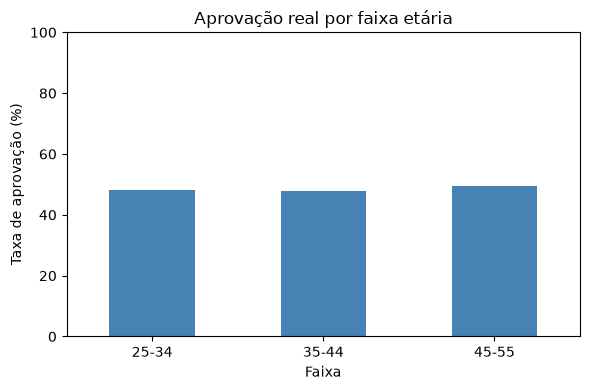

In [3]:
aprov_faixa = df.groupby('Faixa', observed=True)['Best Match'].mean() * 100
print(aprov_faixa.round(1))

print()
print('Correlação entre Age e Best Match:', round(df['Age'].corr(df['Best Match']), 3))

aprov_faixa.plot(kind='bar', color='steelblue', figsize=(6,4))
plt.ylim(0, 100)
plt.ylabel('Taxa de aprovação (%)')
plt.title('Aprovação real por faixa etária')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'idade_aprovacao_faixa.png'), dpi=150)
plt.show()

## 4. Faixa etária x Gênero

A diferença de gênero muda dependendo da idade?

Gender  Female  Male
Faixa               
25-34     35.9  60.8
35-44     35.3  59.5
45-55     35.2  63.3


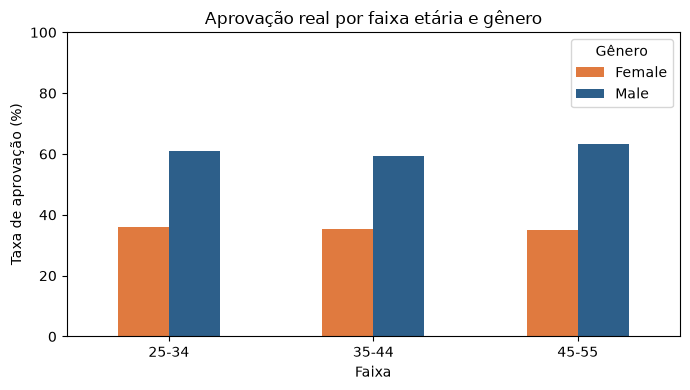

In [4]:
cruz = df.pivot_table(index='Faixa', columns='Gender', values='Best Match',
                      aggfunc='mean', observed=True) * 100
print(cruz.round(1))

cruz.plot(kind='bar', figsize=(7,4), color=['#e07a3f', '#2d5f8a'])
plt.ylim(0, 100)
plt.ylabel('Taxa de aprovação (%)')
plt.title('Aprovação real por faixa etária e gênero')
plt.xticks(rotation=0)
plt.legend(title='Gênero')
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'idade_x_genero_aprovacao.png'), dpi=150)
plt.show()

## 5. Valores SHAP e impacto de `Age` por faixa etária

In [5]:
explainer = shap.TreeExplainer(modelo)
shap_values = explainer.shap_values(X_test, check_additivity=False)
shap_aprovado = shap_values[1] if isinstance(shap_values, list) else shap_values[:, :, 1]

idx_age = list(X_test.columns).index('Age')
idx_gender = list(X_test.columns).index('Gender_Male')

df_idade = pd.DataFrame({
    'shap_age': shap_aprovado[:, idx_age],
    'Faixa': pd.cut(X_test['Age'], bins=bins, labels=labels).values
})

print('SHAP médio de Age por faixa etária:')
print(df_idade.groupby('Faixa', observed=True)['shap_age'].agg(['mean', 'std']).round(4))

SHAP médio de Age por faixa etária:
         mean     std
Faixa                
25-34  0.0002  0.0121
35-44 -0.0021  0.0086
45-55  0.0018  0.0100


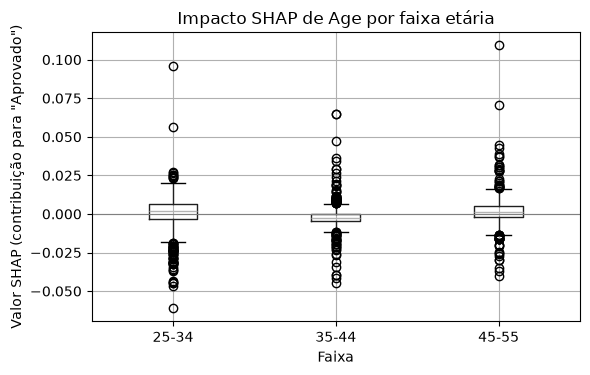

In [6]:
df_idade.boxplot(column='shap_age', by='Faixa', figsize=(6,4))
plt.title('Impacto SHAP de Age por faixa etária')
plt.suptitle('')
plt.ylabel('Valor SHAP (contribuição para "Aprovado")')
plt.axhline(0, color='gray', linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'idade_shap_boxplot.png'), dpi=150)
plt.show()

## 6. Comparação direta: impacto de `Age` x impacto de `Gender_Male`

|SHAP| médio de Age:         0.0065
|SHAP| médio de Gender_Male: 0.1019
Gender_Male pesa ~16x mais que Age


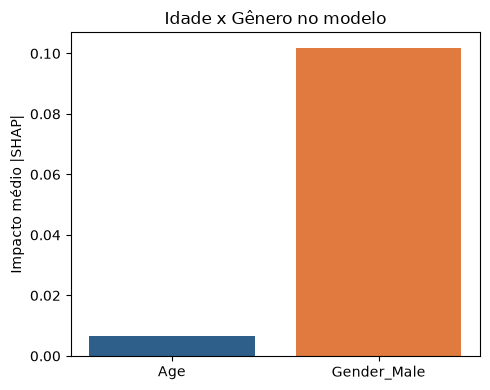

In [7]:
imp_age = np.abs(shap_aprovado[:, idx_age]).mean()
imp_gender = np.abs(shap_aprovado[:, idx_gender]).mean()

print(f'|SHAP| médio de Age:         {imp_age:.4f}')
print(f'|SHAP| médio de Gender_Male: {imp_gender:.4f}')
print(f'Gender_Male pesa ~{imp_gender/imp_age:.0f}x mais que Age')

plt.figure(figsize=(5,4))
plt.bar(['Age', 'Gender_Male'], [imp_age, imp_gender], color=['#2d5f8a', '#e07a3f'])
plt.ylabel('Impacto médio |SHAP|')
plt.title('Idade x Gênero no modelo')
plt.tight_layout()
plt.savefig(os.path.join(PASTA_DADOS, 'idade_vs_genero_shap.png'), dpi=150)
plt.show()